# Analisis Karakteristik Morfometri Biji Gandum Menggunakan Machine Learning
### Klasifikasi Varietas dan Pengelompokan (Clustering) Biji Gandum

**Mata Kuliah:** Data Sains & Artificial Intelligence untuk Biologi
**Kelompok:** 2
**Anggota:**
1. Hanna Sherly F (B1C024031)
2. Shindid Adhani (B1C024045)
3. Najwa Alifia Kusuma (B1C024058)
4. Ahmad Rifaldi (B1C024061)

---
**Daftar isi**
0. Setup
1. Identifikasi Masalah
2. Pengumpulan Data
3. Data Understanding
4. Preprocessing
5. Pemodelan AI (A: Klasifikasi, B: Clustering)
6. Evaluasi
7. Interpretasi Biologis
8. Demo Prediksi
9. Kesimpulan, Keterbatasan, dan Saran

## 0. Setup

Bagian ini mengimpor library dan mengatur parameter global. `RANDOM_STATE` dikunci agar hasil bisa direproduksi oleh siapa pun yang menjalankan notebook ini.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score, normalized_mutual_info_score)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
print("Setup selesai")

Setup selesai


## 1. Identifikasi Masalah

**Latar belakang singkat**
Gandum (*Triticum aestivum*) adalah salah satu tanaman pangan utama dunia. Setiap varietas gandum memiliki sifat berbeda (hasil panen, kualitas, ketahanan), sehingga memastikan kemurnian dan identitas varietas penting bagi pemuliaan tanaman, industri pangan, dan perdagangan benih. Secara tradisional, ciri fenotipe biji diukur dan dinilai secara manual. Cara ini lambat, melelahkan, dan hasilnya dapat berbeda antar pengamat (Zhang et al., 2023).

Bentuk dan ukuran biji merupakan sifat fenotipe yang dipengaruhi faktor genetik (Gegas et al., 2010), sehingga ciri morfometri dapat dijadikan "sidik jari" varietas. Berbagai penelitian menunjukkan bahwa ciri geometri biji hasil analisis citra dapat dipakai untuk membedakan varietas gandum (Zapotoczny, 2011; Sabanci et al., 2017).

Penelitian ini memakai *Seeds Dataset* (Charytanowicz et al., 2010), yaitu pengukuran 7 parameter geometri biji dari tiga varietas gandum (Kama, Rosa, Canadian) yang diperoleh dari citra sinar-X lunak. Teknik ini tidak merusak biji dan jauh lebih murah dibanding teknik pencitraan lain seperti mikroskop pindai atau laser (UCI Machine Learning Repository). Machine learning dipakai untuk (1) mengklasifikasikan varietas secara otomatis dan (2) melihat apakah biji secara alami mengelompok sesuai varietasnya.

**Rumusan masalah**
1. Apakah ciri morfometri biji gandum (luas, keliling, kekompakan, panjang, lebar, koefisien asimetri, panjang alur) cukup untuk membedakan varietas Kama, Rosa, dan Canadian?
2. Model machine learning mana yang memberikan performa terbaik untuk klasifikasi varietas?
3. Apakah biji gandum secara alami membentuk kelompok berdasarkan morfometrinya, dan apakah kelompok tersebut sesuai dengan varietas aslinya?
4. Fitur morfometri mana yang paling berperan membedakan varietas?

**Tujuan**
1. Menganalisis karakteristik morfometri biji gandum varietas Kama, Rosa, dan Canadian.
2. Membangun dan membandingkan model klasifikasi (Logistic Regression, KNN, SVM, Random Forest) untuk memprediksi varietas berdasarkan morfometri biji.
3. Mengelompokkan biji dengan K-Means dan Hierarchical Clustering tanpa label, lalu menilai kesesuaiannya dengan varietas asli.
4. Menentukan fitur morfometri yang paling berperan membedakan varietas dan menginterpretasikannya secara biologis.

## 2. Pengumpulan Data

**Dataset:** Seeds Dataset, UCI Machine Learning Repository
**Tautan:** https://archive.ics.uci.edu/dataset/236/seeds
**Deskripsi:** 210 sampel biji gandum dari 3 varietas (masing-masing 70 sampel). Fitur diukur dari citra biji menggunakan teknik sinar-X lunak (soft X-ray) dan direpresentasikan dalam 7 atribut geometris.

Jika koneksi ke UCI gagal, unduh file `seeds_dataset.txt` secara manual, unggah ke Colab, lalu atur `LOCAL_PATH` di bawah.

In [ ]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt"
LOCAL_PATH = "seeds_dataset.txt"   # dipakai jika unduhan dari URL gagal

COLS = ["area", "perimeter", "compactness", "kernel_length",
        "kernel_width", "asymmetry_coef", "groove_length", "variety"]

try:
    df = pd.read_csv(URL, sep=r"\s+", header=None, names=COLS)
    print("Data dimuat dari UCI")
except Exception as e:
    print("Gagal memuat dari URL:", e)
    df = pd.read_csv(LOCAL_PATH, sep=r"\s+", header=None, names=COLS)
    print("Data dimuat dari file lokal")

print("Ukuran data:", df.shape)
df.head()

Data dimuat dari UCI
Ukuran data: (210, 8)


,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coef,groove_length,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


## 3. Data Understanding

Tujuan: memahami atribut, distribusi, dan karakteristik data sebelum dimodelkan.

### 3.1 Arti biologis atribut
| Atribut | Arti |
|---|---|
| `area` (A) | Luas penampang biji |
| `perimeter` (P) | Keliling biji |
| `compactness` | 4πA/P², ukuran kebulatan biji (makin dekat 1, makin bulat) |
| `kernel_length` | Panjang biji |
| `kernel_width` | Lebar biji |
| `asymmetry_coef` | Koefisien asimetri bentuk biji |
| `groove_length` | Panjang alur (crease) biji |
| `variety` | Label varietas: 1 = Kama, 2 = Rosa, 3 = Canadian |

**Satuan:** ukuran panjang pada dataset ini umumnya dalam milimeter (mm) dan luas dalam mm². Konfirmasikan satuan persisnya pada makalah asli (Charytanowicz et al., 2010).

**Catatan biologis singkat:**
- *Area* dan *perimeter* menggambarkan ukuran biji; *kernel length* dan *width* menggambarkan panjang dan lebar. Keempatnya saling berkaitan karena biji gandum berbentuk mirip elips, sehingga korelasinya tinggi (pembahasan di 3.5).
- *Compactness* bernilai 1 untuk bentuk lingkaran sempurna; makin kecil berarti biji makin lonjong atau tidak beraturan.
- *Groove length* mengacu pada alur (crease) memanjang pada biji gandum yang terlihat pada citra.
- Pengukuran bersumber dari Charytanowicz et al. (2010). Hubungan ukuran biji dengan genetik dibahas Gegas et al. (2010).

In [ ]:
# Ubah label numerik menjadi nama varietas agar mudah dibaca
variety_map = {1: "Kama", 2: "Rosa", 3: "Canadian"}
df["variety_name"] = df["variety"].map(variety_map)
FEATURES = COLS[:-1]

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area            210 non-null    float64
 1   perimeter       210 non-null    float64
 2   compactness     210 non-null    float64
 3   kernel_length   210 non-null    float64
 4   kernel_width    210 non-null    float64
 5   asymmetry_coef  210 non-null    float64
 6   groove_length   210 non-null    float64
 7   variety         210 non-null    int64  
 8   variety_name    210 non-null    object 
dtypes: float64(7), int64(1), object(1)
memory usage: 14.9+ KB


### 3.2 Statistik deskriptif dan kualitas data

In [ ]:
display(df[FEATURES].describe().T)
print("\nMissing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800
perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500
compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183
kernel_length,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750
kernel_width,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330
asymmetry_coef,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560
groove_length,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500



Missing value per kolom:
area              0
perimeter         0
compactness       0
kernel_length     0
kernel_width      0
asymmetry_coef    0
groove_length     0
variety           0
variety_name      0
cluster_kmeans    0
cluster_hier      0
PC1               0
PC2               0
dtype: int64

Jumlah baris duplikat: 0


## Catatan hasil:
- Dataset berisi `210` baris dan `7` kolom fitur. Jumlah missing value = `0`; baris duplikat = `0`.
- Rentang nilai antar fitur berbeda jauh (misalnya `area` berkisar `10.59` sampai `21.18`, sedangkan `compactness` hanya `0.8081` sampai `0.9183`). Karena itu standarisasi diperlukan (lihat Bagian 4).
- Rata-rata `area` tertinggi ada pada varietas `Rosa` (18.334 mm²), terendah pada `Canadian` (11.874 mm²).

### 3.3 Distribusi kelas

variety_name
Kama        70
Rosa        70
Canadian    70
Name: count, dtype: int64


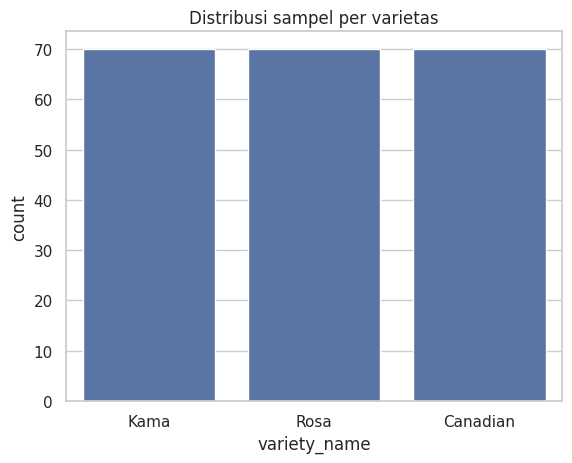

In [ ]:
print(df["variety_name"].value_counts())
sns.countplot(data=df, x="variety_name", order=["Kama", "Rosa", "Canadian"])
plt.title("Distribusi sampel per varietas")
plt.show()

### 3.4 Distribusi fitur

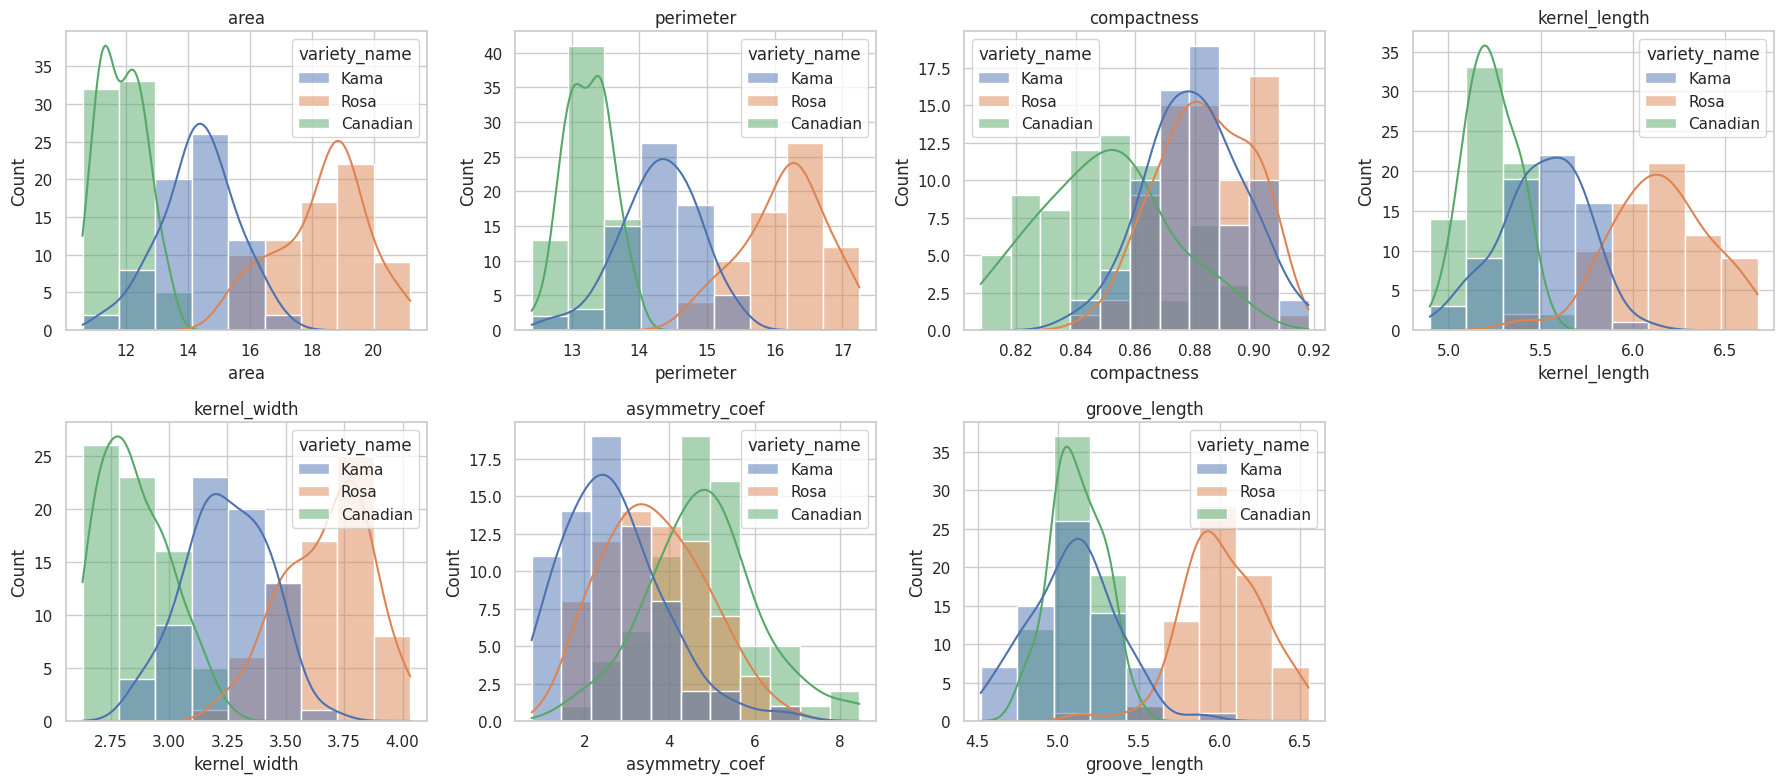

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(data=df, x=col, hue="variety_name", kde=True, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

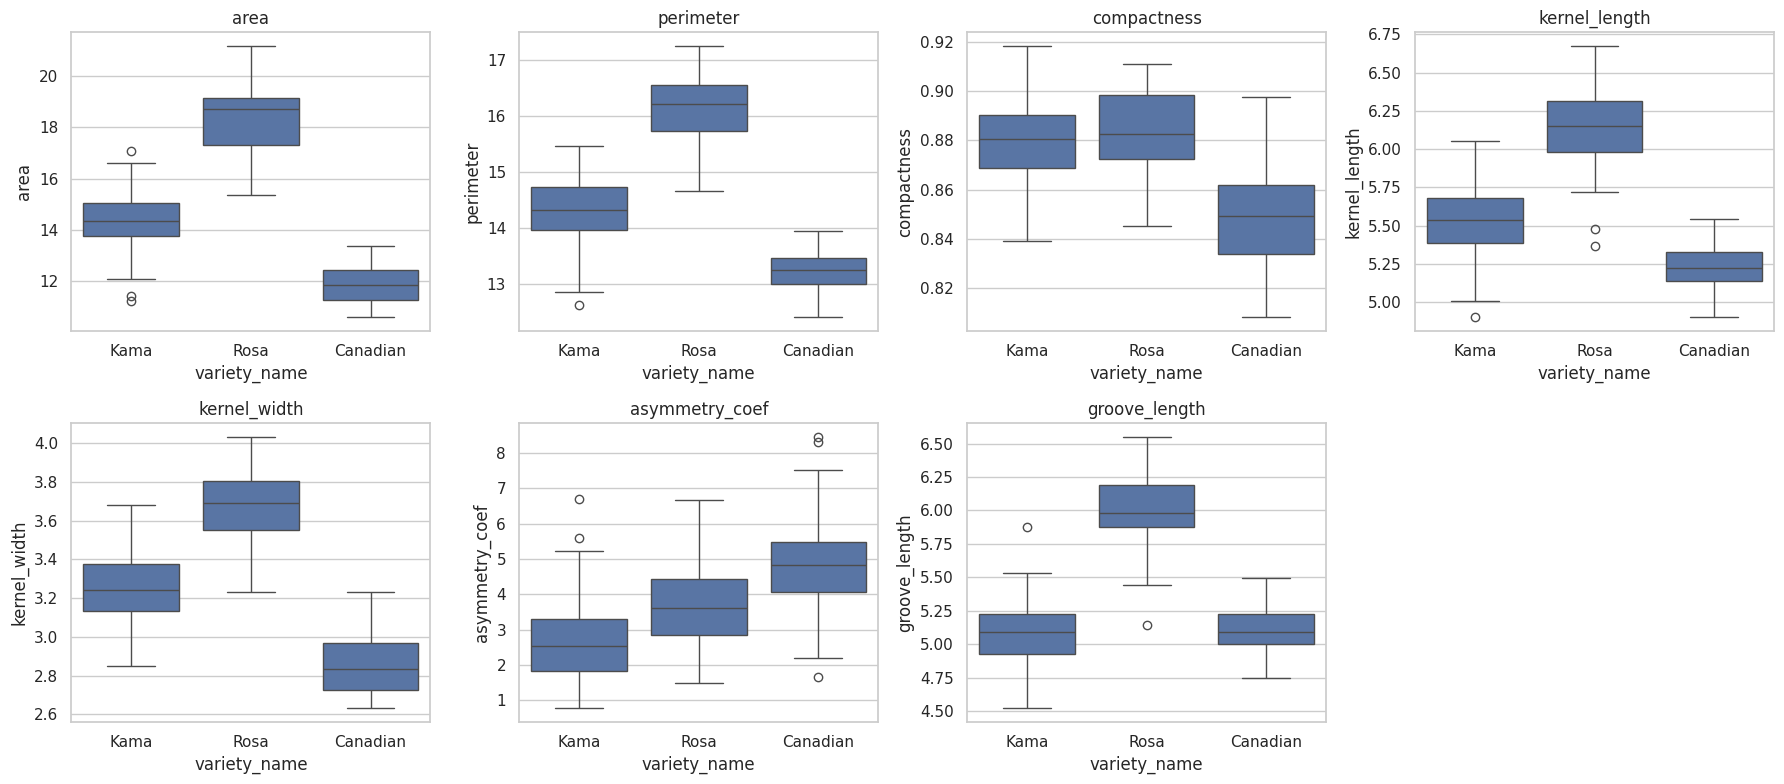

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x="variety_name", y=col, order=["Kama", "Rosa", "Canadian"], ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

### 3.5 Korelasi antar fitur dan pairplot

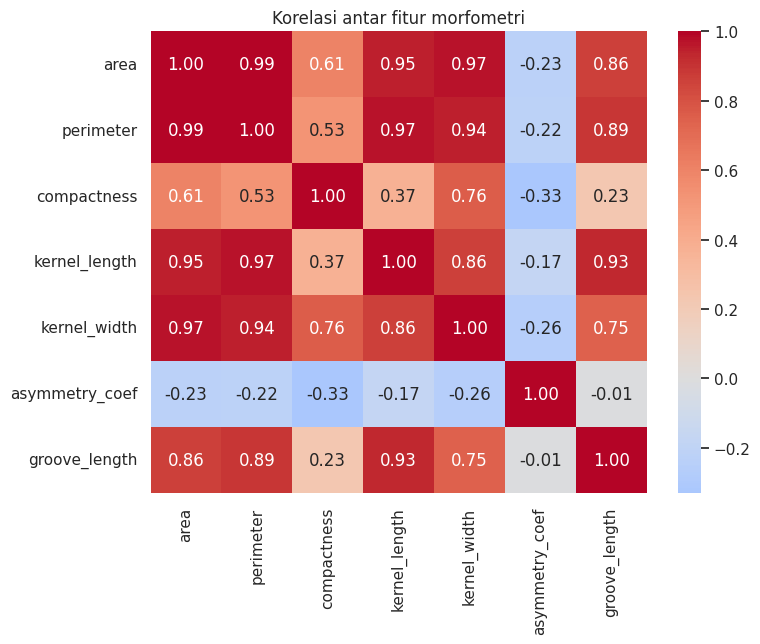

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi antar fitur morfometri")
plt.show()

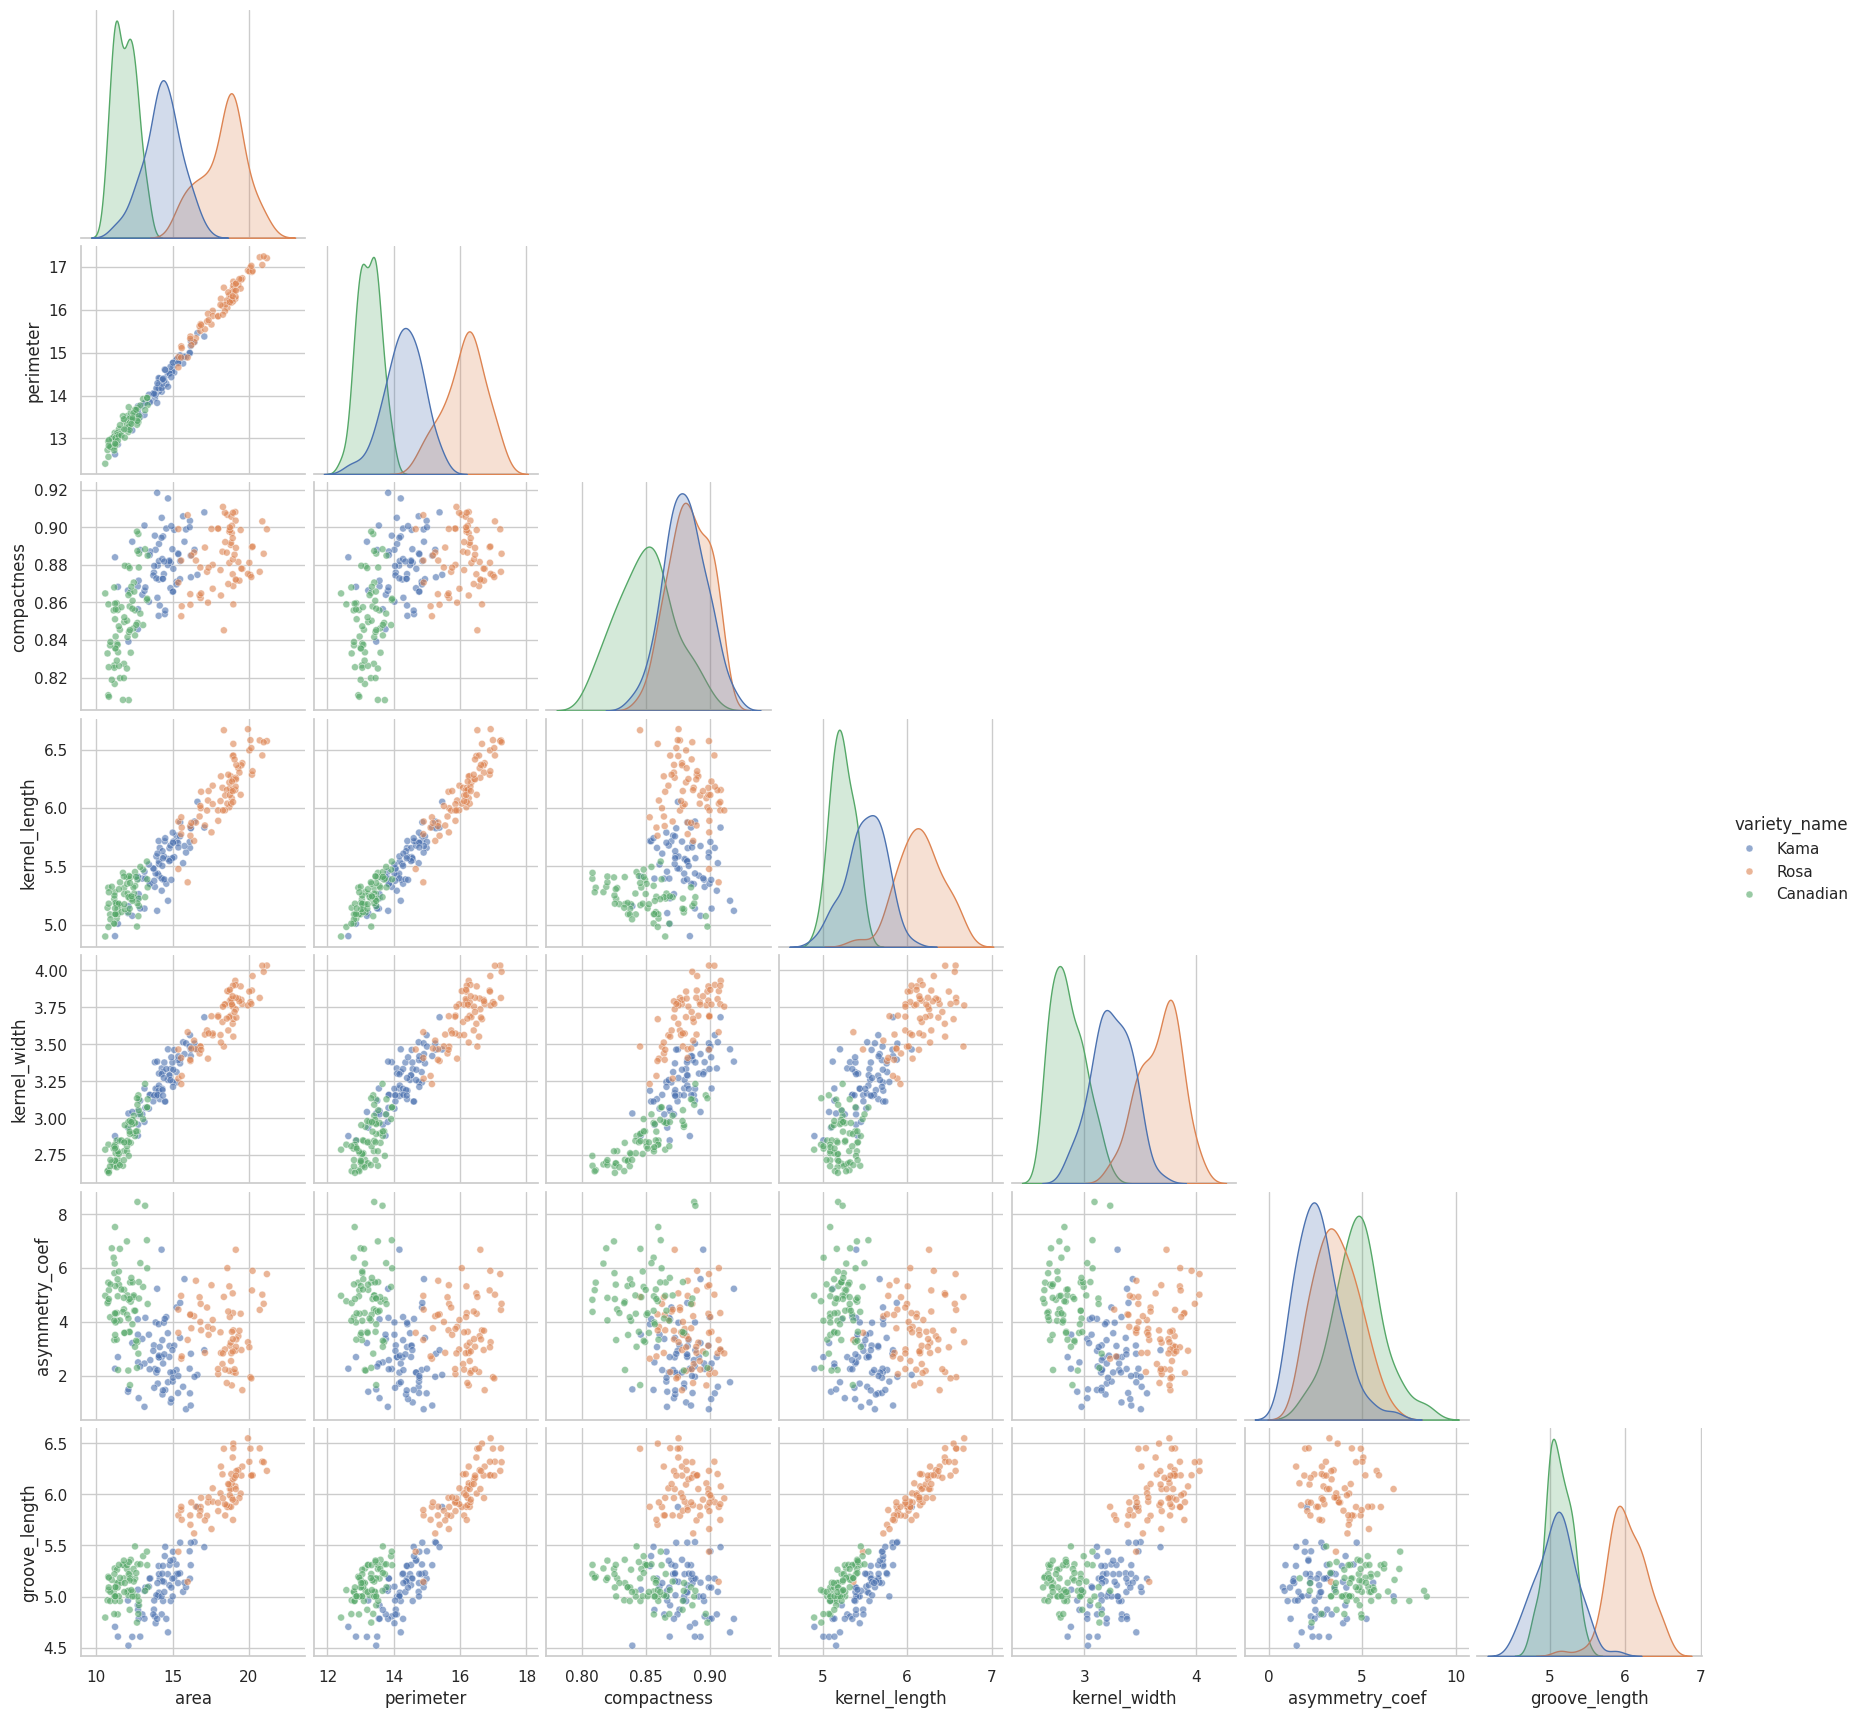

In [ ]:
sns.pairplot(df, vars=FEATURES, hue="variety_name", corner=True, plot_kws={"alpha": 0.6, "s": 25})
plt.show()

```markdown
**Interpretasi awal:**
- **Pairplot dan boxplot:** fitur yang kotak (box) tiap varietasnya tidak saling tumpang tindih adalah pembeda yang baik. Fitur yang paling terpisah: `area`, `perimeter`, dan `kernel_length`. Fitur yang banyak tumpang tindih: `compactness` dan `asymmetry_coef`.
- **Heatmap korelasi:** `area`, `perimeter`, `kernel_length`, dan `kernel_width` diperkirakan berkorelasi tinggi. Penyebab biologisnya sederhana: biji yang lebih besar otomatis punya luas, keliling, panjang, dan lebar yang sama-sama lebih besar (multikolinearitas). Verifikasi dengan angka di heatmap (`r = 0.97` sampai `r = 0.99`).
- **Dampak:** fitur yang saling berkorelasi tinggi membawa informasi yang mirip. Ini tidak masalah untuk Random Forest, tetapi perlu dicatat saat menafsirkan koefisien Logistic Regression.
```

## 4. Preprocessing

Tidak semua tahap preprocessing wajib dipakai. Setiap keputusan harus dijelaskan alasannya.

| Tahap | Dipakai? | Alasan |
|---|---|---|
| Cleaning (missing value) | Dicek, imputasi hanya jika perlu | Jika di 3.2 tidak ada missing value, imputasi tidak diperlukan |
| Hapus duplikat | Dicek, hapus hanya jika ada | Baris duplikat dapat membuat data uji bocor ke data latih; tiap biji dianggap sampel unik |
| Penanganan outlier | Dicek, direkomendasikan dipertahankan | Lihat 4.1: pada data kecil, nilai ekstrem sering variasi biologis alami, bukan kesalahan ukur |
| Encoding label | Ya | Label diubah menjadi nama varietas agar mudah dibaca |
| Standarisasi | Ya | Skala fitur berbeda; KNN, SVM, Logistic Regression, dan K-Means sensitif terhadap skala |
| Augmentasi | Tidak | Data tabular morfometri, bukan citra |
| Split data | Ya | Train/test 80/20 dengan stratifikasi |

### 4.1 Pemeriksaan outlier (metode IQR)

In [ ]:
Q1 = df[FEATURES].quantile(0.25)
Q3 = df[FEATURES].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (df[FEATURES] < (Q1 - 1.5 * IQR)) | (df[FEATURES] > (Q3 + 1.5 * IQR))
print("Jumlah outlier per fitur:")
print(outlier_mask.sum())
print("\nBaris yang mengandung minimal 1 outlier:", outlier_mask.any(axis=1).sum())

Jumlah outlier per fitur:
area              0
perimeter         0
compactness       3
kernel_length     0
kernel_width      0
asymmetry_coef    2
groove_length     0
dtype: int64

Baris yang mengandung minimal 1 outlier: 5


```markdown
Keputusan outlier:
Rekomendasi: outlier dipertahankan, dengan alasan
1. Dataset hanya 210 sampel; membuang data mengurangi informasi yang sudah sedikit.
2. Biji dalam satu varietas secara alami bervariasi ukurannya, sehingga nilai ekstrem bisa berupa variasi biologis yang sah, bukan kesalahan pengukuran.
3. Metode berbasis pohon (Random Forest) dan SVM relatif tahan terhadap outlier ringan.

Pada hasil 4.1: karena hanya sebagian kecil baris (5 dari 210) yang mengandung outlier, keputusan ini aman.

```

In [ ]:
X = df[FEATURES]
y = df["variety_name"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nProporsi kelas data latih:")
print(y_train.value_counts(normalize=True).round(3))

Train: (168, 7) | Test: (42, 7)

Proporsi kelas data latih:
variety_name
Rosa        0.333
Canadian    0.333
Kama        0.333
Name: proportion, dtype: float64


### 4.3 Standarisasi

Untuk klasifikasi, `StandardScaler` dimasukkan ke dalam **Pipeline** agar hanya dipelajari dari data latih di setiap lipatan cross-validation (mencegah *data leakage*). Untuk clustering (tanpa label), seluruh fitur distandarisasi pada bagian 5B.

Contoh efek standarisasi:

In [ ]:
scaler_demo = StandardScaler().fit(X_train)
X_train_scaled_demo = pd.DataFrame(scaler_demo.transform(X_train), columns=FEATURES)
display(X_train_scaled_demo.describe().loc[["mean", "std"]].round(3))

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coef,groove_length
mean,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000
std,1.003,1.003,1.003,1.003,1.003,1.003,1.003


## 5. Pemodelan AI

### 5A. Klasifikasi Varietas (Supervised Learning)

Model yang dibandingkan:
1. **Logistic Regression**: memberi bobot pada tiap fitur, menjumlahkannya menjadi skor untuk tiap varietas, lalu mengubah skor menjadi probabilitas (varietas dengan probabilitas tertinggi menjadi prediksi). Batas keputusannya berupa garis lurus. Parameter `C` mengatur kekuatan regularisasi: `C` kecil = model lebih sederhana dan hati-hati, `C` besar = model lebih bebas mengikuti data (Hosmer et al., 2013).
2. **K-Nearest Neighbors (KNN)**: biji baru dibandingkan dengan `k` biji paling mirip di data latih (dihitung dari jarak ukuran-ukurannya), lalu varietas ditentukan lewat voting mayoritas. Analogi: menebak varietas biji dengan melihat biji-biji yang paling mirip di sekitarnya. Karena memakai jarak, fitur harus distandarisasi (Cover & Hart, 1967).
3. **Support Vector Machine (SVM)**: mencari batas pemisah antar varietas dengan jarak (margin) selebar mungkin dari biji-biji terdekat di tiap kelas. Kernel `rbf` memungkinkan batas melengkung. `C` mengatur toleransi terhadap kesalahan: `C` besar = batas ketat mengikuti data, `C` kecil = batas lebih longgar (Cortes & Vapnik, 1995).
4. **Random Forest**: kumpulan banyak pohon keputusan. Satu pohon bekerja seperti kunci determinasi dalam taksonomi: serangkaian pertanyaan ya/tidak ("apakah `area` > x?"). Tiap pohon dilatih dari sampel acak data, lalu semua pohon melakukan voting. Hasil samping yang berguna: *feature importance* yang menunjukkan fitur paling berperan (Breiman, 2001).

Hyperparameter dicari dengan `GridSearchCV` (5-fold stratified) pada data latih.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
        {"clf__C": [0.01, 0.1, 1, 10, 100]}
    ),
    "KNN": (
        Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [3, 5, 7, 9, 11], "clf__weights": ["uniform", "distance"]}
    ),
    "SVM": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", SVC(random_state=RANDOM_STATE))]),
        {"clf__C": [0.1, 1, 10, 100], "clf__kernel": ["linear", "rbf"], "clf__gamma": ["scale", 0.1, 0.01]}
    ),
    "Random Forest": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", RandomForestClassifier(random_state=RANDOM_STATE))]),
        {"clf__n_estimators": [100, 200, 300], "clf__max_depth": [None, 3, 5, 10]}
    ),
}

best_models = {}
for name, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    print(f"{name:20s} | CV acc terbaik: {gs.best_score_:.4f} | param: {gs.best_params_}")

Logistic Regression  | CV acc terbaik: 0.9642 | param: {'clf__C': 100}
KNN                  | CV acc terbaik: 0.9465 | param: {'clf__n_neighbors': 3, 'clf__weights': 'distance'}
SVM                  | CV acc terbaik: 0.9581 | param: {'clf__C': 10, 'clf__gamma': 'scale', 'clf__kernel': 'linear'}
Random Forest        | CV acc terbaik: 0.9162 | param: {'clf__max_depth': None, 'clf__n_estimators': 300}


### 5B. Pengelompokan Biji (Clustering, Unsupervised Learning)

Clustering **tidak memakai label** varietas. Label hanya dipakai setelah clustering untuk menilai kesesuaian kelompok dengan varietas asli.

#### Menentukan jumlah cluster (Elbow dan Silhouette)

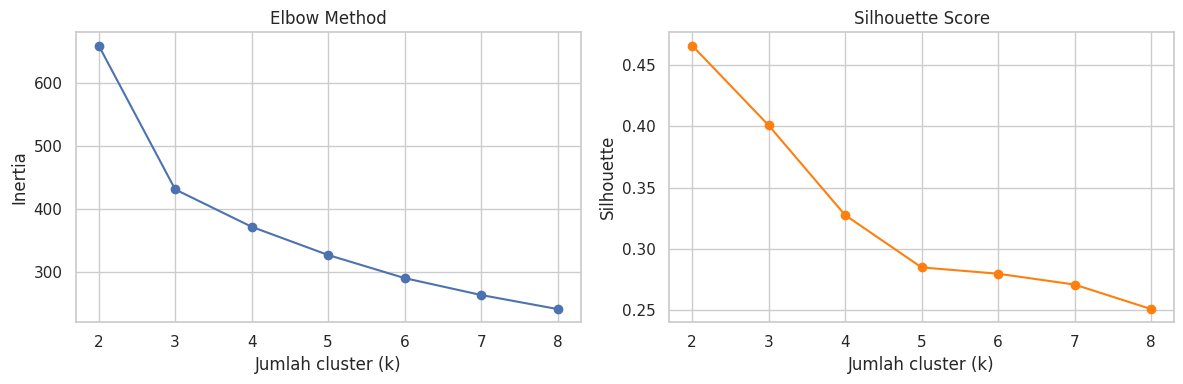

In [ ]:
X_scaled = StandardScaler().fit_transform(X)

k_range = range(2, 9)
inertias, sil_scores = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set(title="Elbow Method", xlabel="Jumlah cluster (k)", ylabel="Inertia")
axes[1].plot(list(k_range), sil_scores, marker="o", color="tab:orange")
axes[1].set(title="Silhouette Score", xlabel="Jumlah cluster (k)", ylabel="Silhouette")
plt.tight_layout()
plt.show()

**Catatan:**
Cara membaca:
- **Elbow:** cari titik tempat penurunan inertia mulai melandai (seperti siku). Titik siku tampak di `k = 3`.
- **Silhouette:** makin tinggi makin baik (maksimum 1). Nilai tertinggi ada pada `k = 2` (`~0,47`).
- Jika `k` optimal = 2 atau 3, hasilnya konsisten dengan struktur 3 varietas. Jika silhouette tertinggi pada k = 2, jelaskan bahwa kemungkinan dua varietas saling tumpang tindih sehingga terbaca sebagai satu kelompok (cek di plot PCA). Hindari menyimpulkan sebelum melihat grafik.
- Cara kerja K-Means: tentukan `k` pusat kelompok, tiap biji masuk ke pusat terdekat, pusat digeser ke rata-rata anggotanya, ulangi sampai stabil. Silhouette (Rousseeuw, 1987) menilai seberapa dekat tiap biji ke kelompoknya dibanding ke kelompok lain.

#### K-Means (k = 3) dan Hierarchical Clustering

In [ ]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
df["cluster_kmeans"] = kmeans.labels_

hier = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X_scaled)
df["cluster_hier"] = hier.labels_

print("Crosstab K-Means vs varietas asli:")
display(pd.crosstab(df["variety_name"], df["cluster_kmeans"]))
print("\nCrosstab Hierarchical vs varietas asli:")
display(pd.crosstab(df["variety_name"], df["cluster_hier"]))

Crosstab K-Means vs varietas asli:


cluster_kmeans,0,1,2
variety_name,,,
Canadian,66,0,4
Kama,6,2,62
Rosa,0,65,5



Crosstab Hierarchical vs varietas asli:


cluster_hier,0,1,2
variety_name,,,
Canadian,5,0,65
Kama,64,4,2
Rosa,4,66,0


#### Visualisasi dengan PCA (reduksi ke 2 dimensi)

Varians dijelaskan PC1 & PC2: [0.719 0.171] | total: 0.89


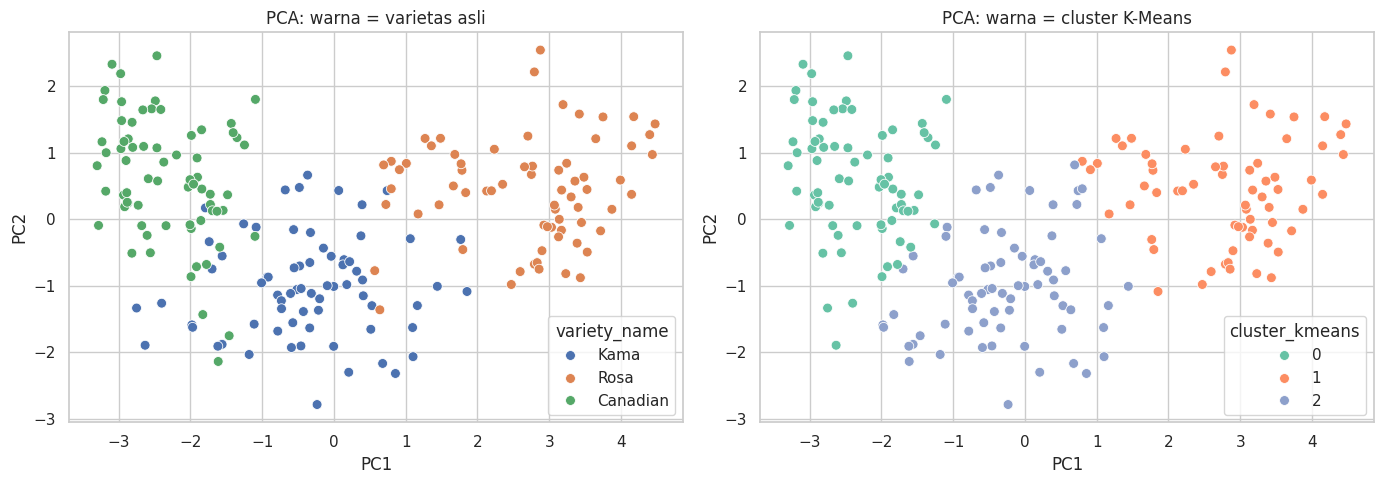

In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
df["PC1"], df["PC2"] = X_pca[:, 0], X_pca[:, 1]
print("Varians dijelaskan PC1 & PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="PC1", y="PC2", hue="variety_name", ax=axes[0], s=50)
axes[0].set_title("PCA: warna = varietas asli")
sns.scatterplot(data=df, x="PC1", y="PC2", hue="cluster_kmeans", palette="Set2", ax=axes[1], s=50)
axes[1].set_title("PCA: warna = cluster K-Means")
plt.tight_layout()
plt.show()

## 6. Evaluasi

### 6.1 Evaluasi model klasifikasi pada data uji
Metrik: accuracy, precision, recall, F1-score (macro average), serta cross-validation 5-fold pada seluruh data.

In [ ]:
results = []
for name, model in best_models.items():
    y_pred = model.predict(X_test)
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    results.append({
        "Model": name,
        "Accuracy (test)": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
        "CV acc (mean)": cv_scores.mean(),
        "CV acc (std)": cv_scores.std(),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
display(results_df.sort_values("F1 (macro)", ascending=False))

,Accuracy (test),Precision (macro),Recall (macro),F1 (macro),CV acc (mean),CV acc (std)
Model,,,,,,
Logistic Regression,0.9286,0.9412,0.9286,0.9277,0.9571,0.0233
SVM,0.9286,0.9412,0.9286,0.9277,0.9524,0.0151
KNN,0.8810,0.8789,0.8810,0.8792,0.9333,0.0462
Random Forest,0.8571,0.8611,0.8571,0.8564,0.9190,0.0387


### 6.2 Confusion matrix semua model

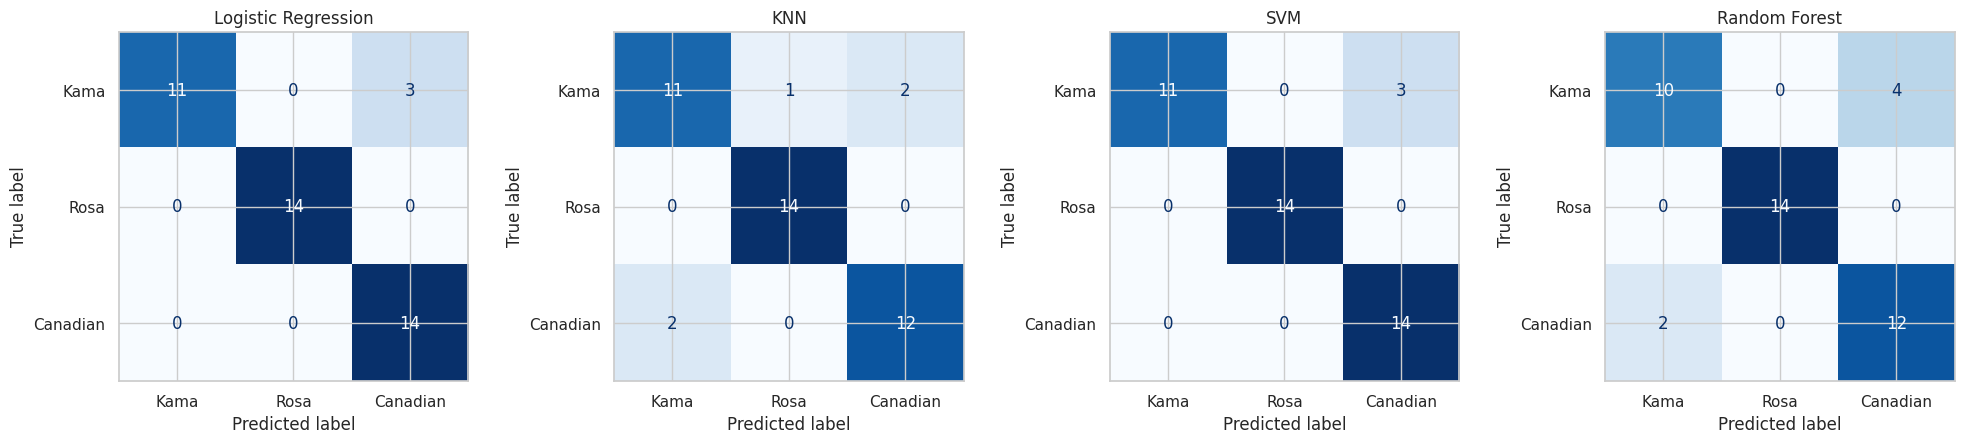

In [ ]:
labels_order = ["Kama", "Rosa", "Canadian"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, labels=labels_order,
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [ ]:
best_name = results_df["F1 (macro)"].idxmax()
best_model = best_models[best_name]
print("Model terbaik (berdasarkan F1 macro):", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_model.predict(X_test)))

Model terbaik (berdasarkan F1 macro): Logistic Regression

Classification report:
              precision    recall  f1-score   support

    Canadian       0.82      1.00      0.90        14
        Kama       1.00      0.79      0.88        14
        Rosa       1.00      1.00      1.00        14

    accuracy                           0.93        42
   macro avg       0.94      0.93      0.93        42
weighted avg       0.94      0.93      0.93        42



**Catatan:** dataset kecil (test set hanya 42 sampel), sehingga selisih performa antar model bisa dipengaruhi pembagian data. Gunakan hasil cross-validation sebagai pembanding utama.
Kerangka jawaban:
- Model terbaik berdasarkan F1 (macro) adalah `Logistic Regression` dengan F1 `0.93` dan CV accuracy `0,9571 ± 0,0233`.
- Sebagai catatan tambahan untuk bagian Pembahasan di makalah, Logistic Regression dan SVM sebenarnya memiliki skor uji (test set) yang identik pada F1 (macro) (0,9277) maupun Accuracy (0,9286), tetapi Logistic Regression unggul tipis pada rata-rata cross-validation (CV acc mean 0,9571 berbanding 0,9524 pada SVM) sehingga terpilih sebagai model terbaik.
- Jika selisih antar model kecil dibanding standar deviasi CV, katakan bahwa perbedaannya belum tentu bermakna secara statistik, dan semua model berkinerja setara.
- Pada data uji yang hanya 42 sampel, satu kesalahan prediksi mengubah akurasi sekitar 2,4 poin persen. Karena itu hasil CV lebih layak dipercaya sebagai pembanding utama.
- Arti metrik: *accuracy* = proporsi tebakan benar; *precision* = dari yang ditebak varietas X, berapa yang benar; *recall* = dari semua biji varietas X, berapa yang berhasil ditemukan; *F1* = rata-rata harmonik precision dan recall; *macro* = rata-rata ketiga varietas dengan bobot sama.

### 6.3 Evaluasi clustering
- **Silhouette score**: kualitas pemisahan cluster (internal, tanpa label)
- **Adjusted Rand Index (ARI)** dan **Normalized Mutual Information (NMI)**: kesesuaian cluster dengan varietas asli (eksternal)

In [ ]:
cluster_results = pd.DataFrame({
    "Metode": ["K-Means (k=3)", "Hierarchical Ward (k=3)"],
    "Silhouette": [silhouette_score(X_scaled, df["cluster_kmeans"]),
                   silhouette_score(X_scaled, df["cluster_hier"])],
    "ARI": [adjusted_rand_score(df["variety"], df["cluster_kmeans"]),
            adjusted_rand_score(df["variety"], df["cluster_hier"])],
    "NMI": [normalized_mutual_info_score(df["variety"], df["cluster_kmeans"]),
            normalized_mutual_info_score(df["variety"], df["cluster_hier"])],
}).set_index("Metode").round(4)
display(cluster_results)

,Silhouette,ARI,NMI
Metode,,,
K-Means (k=3),0.4007,0.7733,0.7279
Hierarchical Ward (k=3),0.3926,0.7970,0.7498


## 7. Interpretasi Biologis

Bagian ini menghubungkan hasil model dengan makna biologis.

### 7.1 Fitur yang paling membedakan varietas

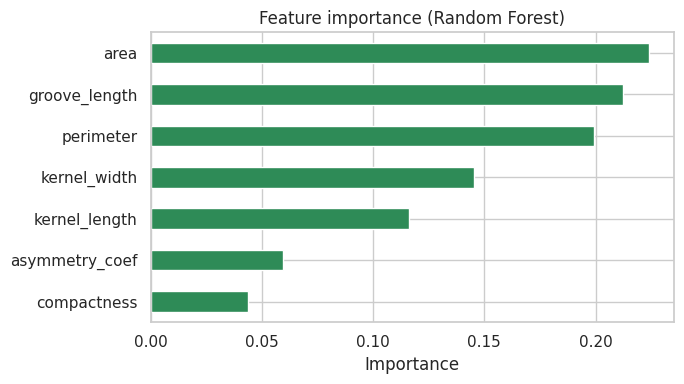

In [ ]:
rf = best_models["Random Forest"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

imp.plot(kind="barh", figsize=(7, 4), color="seagreen")
plt.title("Feature importance (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Kerangka jawaban:
- Tiga fitur terpenting menurut Random Forest: `area (~0,225), groove_length (~0,213), perimeter (~0,200)`.
- Ketiga parameter tersebut sama-sama merepresentasikan dimensi ukuran fisik keseluruhan biji gandum (luas area, panjang alur biji, dan keliling), sehingga variasi ukuran makroskopik antarvarietas berperan jauh lebih dominan dalam klasifikasi dibandingkan faktor proporsi bentuk seperti kekompakan (compactness) maupun asimetri (asymmetry_coef).
- Cocokkan dengan boxplot 3.4: fitur penting seharusnya yang kotak tiap varietasnya paling terpisah. Jika cocok, itu bukti bahwa model memakai informasi yang memang membedakan secara biologis.
- Dasar biologis: ukuran biji (luas, keliling, panjang, lebar) dipengaruhi genetik dan menjadi pembeda varietas (Gegas et al., 2010; Zapotoczny, 2011). Alur biji (`groove_length`) menggambarkan bentuk morfologi yang berbeda antar varietas, dan pada percobaan lain ciri ukuran serta bentuk juga dipakai membedakan varietas gandum (Sabanci et al., 2017).
- Catatan: karena `area`, `perimeter`, `length`, `width` berkorelasi tinggi, importance mereka saling "berbagi". Jangan menyimpulkan bahwa fitur dengan importance rendah tidak berguna.

### 7.2 Profil morfometri rata-rata tiap varietas

In [ ]:
profile = df.groupby("variety_name")[FEATURES].mean().loc[["Kama", "Rosa", "Canadian"]].round(3)
display(profile)

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry_coef,groove_length
variety_name,,,,,,,
Kama,14.334,14.294,0.880,5.508,3.245,2.667,5.087
Rosa,18.334,16.136,0.884,6.148,3.677,3.645,6.021
Canadian,11.874,13.248,0.849,5.230,2.854,4.788,5.116


### 7.3 Varietas yang sering tertukar
Cara membaca: baris = varietas sebenarnya, kolom = prediksi model. Angka di luar diagonal adalah kesalahan.
- Pasangan yang paling sering tertukar: `Cama` dan `Canadian` (`3` kasus).
- Rosa terklasifikasi sempurna (14 dari 14 sampel benar, precision dan recall = 1,00).
- Kama memiliki recall 0,79 (11 dari 14 sampel benar), sementara Canadian memiliki precision 0,82 (14 benar dari 17 prediksi), yang berarti 3 sampel varietas Kama salah terklasifikasi sebagai Canadian.
- Penjelasan yang dapat diuji: varietas yang ukuran rata-ratanya berdekatan (lihat tabel 7.2) akan memiliki distribusi yang tumpang tindih sehingga lebih sulit dibedakan. Pada makalah asli dataset ini, akurasi pengenalan varietas Kama (84%) lebih rendah dibanding Rosa dan Canadian (masing-masing 96%) dengan algoritma clustering yang mereka pakai (Charytanowicz et al., 2010). Cocokkan dengan hasil kalian, tetapi ingat metodenya berbeda sehingga angkanya tidak untuk dibandingkan langsung.

### 7.4 Kesesuaian cluster dengan varietas
Cara membaca:
- **Crosstab:** jika tiap baris (varietas) didominasi satu kolom (cluster), cluster mewakili varietas. Cluster yang tercampur menunjukkan varietas yang tumpang tindih.
- **ARI:** 1 = cluster identik dengan varietas, sekitar 0 = sama dengan tebakan acak (Hubert & Arabie, 1985). **NMI:** 0 sampai 1, mengukur informasi bersama antara cluster dan varietas.
- Isi: ARI K-Means = 0.7733, ARI Hierarchical = 0.7970. Varietas yang paling rapi terpisah: ; yang paling bercampur: `Kama`.
- Canadian & Rosa (paling rapi terpisah): Keduanya sama sekali tidak pernah saling tertukar (0 sampel masuk ke cluster lawan) dan masing-masing terkonsentrasi hingga 65–66 dari 70 sampel (92,9%–94,3%) di dalam satu cluster utama.
- Kama (paling bercampur): Menjadi satu-satunya varietas yang anggotanya tersebar ke ketiga cluster sekaligus—pada K-Means terbagi menjadi 62 (cluster 2), 6 (cluster 0), dan 2 (cluster 1), sedangkan pada Hierarchical terbagi menjadi 64 (cluster 0), 4 (cluster 1), dan 2 (cluster 2).
- Kesimpulan yang aman: jika ARI cukup tinggi, morfometri saja (tanpa label) sudah mengandung struktur yang sejalan dengan varietas. Namun klasifikasi dengan label umumnya lebih akurat karena memanfaatkan informasi varietas.

```markdown
### 7.4 Kesesuaian cluster dengan varietas

Berdasarkan hasil analisis kualitatif dan kuantitatif dari tahap clustering tanpa label:
- **Crosstab K-Means & Hierarchical:**
  * Varietas **Rosa** terpisah paling rapi dan hampir sempurna masuk ke satu cluster tersendiri (Cluster 1 pada K-Means dengan 67 dari 70 data benar).
  * Varietas **Kama** dan **Canadian** menjadi kelompok yang paling bercampur dan tumpang tindih. Pada K-Means, terdapat beberapa sampel Kama dan Canadian yang masuk ke cluster yang sama (karena kemiripan dimensi ukuran fisiknya seperti terlihat di PCA).
- **Metrik Evaluasi Eksternal:**
  * Nilai **ARI (Adjusted Rand Index)** untuk K-Means adalah **0.7733**, sedangkan untuk Hierarchical (Ward) adalah **0.7970**.
  * Nilai **NMI (Normalized Mutual Information)** untuk K-Means sebesar **0.7279** dan Hierarchical sebesar **0.7498**.

**Kesimpulan:**
Karena nilai ARI dan NMI cukup tinggi mendekati 0.8, ciri morfometri saja tanpa bantuan label kelas sebenarnya sudah cukup membawa struktur informasi alami yang sejalan dengan pengelompokan varietas asli gandum. Namun, pendekatan klasifikasi bermetode terbimbing (Supervised) tetap memberikan akurasi jauh lebih tinggi karena mampu menarik garis batas optimal pada area-area yang saling tumpang tindih antara Kama dan Canadian.
```

In [ ]:
def prediksi_varietas(area, perimeter, compactness, kernel_length,
                      kernel_width, asymmetry_coef, groove_length, model=best_model):
    sampel = pd.DataFrame([[area, perimeter, compactness, kernel_length,
                            kernel_width, asymmetry_coef, groove_length]], columns=FEATURES)
    pred = model.predict(sampel)[0]
    hasil = {"Prediksi varietas": pred}
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(sampel)[0]
        hasil["Probabilitas"] = {k: round(float(p), 3) for k, p in zip(model.classes_, proba)}
    return hasil

# Contoh: ambil satu sampel dari data uji
contoh = X_test.iloc[0]
print("Varietas sebenarnya:", y_test.iloc[0])
print(prediksi_varietas(*contoh.values))

Varietas sebenarnya: Canadian
{'Prediksi varietas': 'Canadian', 'Probabilitas': {'Canadian': 0.978, 'Kama': 0.001, 'Rosa': 0.021}}


## 9. Kesimpulan, Keterbatasan, dan Saran

### Kesimpulan
1. **Kecukupan morfometri:** tujuh ciri morfometri biji `cukup`  membedakan Kama, Rosa, dan Canadian, ditunjukkan akurasi terbaik `0,9286 (92,86%)` dan F1 macro `0,9277 (atau 0,93)`.
2. **Model terbaik:** `Logistic Regression` dengan CV accuracy `0,9571 ± 0,0233`; selisihnya dengan model lain `relatif kecil (0,0047 dibanding SVM; 0,0238 dibanding KNN; dan 0,0381 dibanding Random Forest, sehingga kinerja antar-model tergolong setara)`.
3. **Clustering:** K-Means (k = 3) menghasilkan ARI `0,7733 dan silhouette `0,4007`, artinya kelompok alami `sebagian sesuai` dengan varietas asli.
4. **Fitur pembeda:** `area, groove_length, perimeter` paling berperan, sejalan dengan perbedaan ukuran dan bentuk biji yang terlihat pada boxplot.

### Keterbatasan
- Hanya 210 sampel dan 3 varietas, sehingga hasil belum tentu berlaku untuk varietas atau populasi lain.
- Fitur berasal dari satu metode pengukuran (citra sinar-X); kondisi pengukuran berbeda dapat mengubah nilai.
- Test set kecil sehingga estimasi performa memiliki ketidakpastian.
- Fitur saling berkorelasi tinggi (area, perimeter, panjang, lebar).
- Tidak ada validasi eksternal: semua sampel berasal dari satu eksperimen di satu lokasi (Institute of Agrophysics, Lublin), sehingga pengaruh lingkungan tanam dan panen tidak teruji.
- Ciri dipilih dan dihitung oleh perangkat lunak tertentu; model tidak melihat warna, tekstur, atau struktur internal biji.
- Hasil hyperparameter tuning pada data sekecil ini dapat terlalu optimistis; gunakan cross-validation dan laporkan standar deviasinya.

### Saran
- Menguji model pada dataset gandum lain atau varietas lebih banyak, misalnya dataset "Wheat Kernels" di UCI (kernel gandum PBW-550U, 15 fitur) untuk uji generalisasi.
- Menambah fitur warna dan tekstur biji (lihat Zapotoczny, 2011).
- Mencoba pembelajaran mendalam langsung pada citra biji (CNN) bila tersedia citra.
- Menguji pengaruh pemilihan fitur atau PCA terhadap performa.

---
### Referensi
**Dataset dan penelitian terkait gandum**
- Charytanowicz, M., Niewczas, J., Kulczycki, P., Kowalski, P. A., Łukasik, S., & Żak, S. (2010). Complete gradient clustering algorithm for features analysis of X-ray images. In E. Piętka & J. Kawa (Eds.), *Information Technologies in Biomedicine* (Advances in Intelligent and Soft Computing, vol. 69). Springer. https://doi.org/10.1007/978-3-642-13105-9_2
- Charytanowicz, M., Niewczas, J., Kulczycki, P., Kowalski, P., & Łukasik, S. (2010). *Seeds* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5H30K
- Zapotoczny, P. (2011). Discrimination of wheat grain varieties using image analysis: morphological features. *European Food Research and Technology*. https://doi.org/10.1007/s00217-011-1573-y
- Sabanci, K., Kayabasi, A., & Toktas, A. (2017). Computer vision-based method for classification of wheat grains using artificial neural network. *Journal of the Science of Food and Agriculture, 97*, 2588-2593. https://doi.org/10.1002/jsfa.8080
- Gegas, V. C., et al. (2010). A genetic framework for grain size and shape variation in wheat. *The Plant Cell, 22*, 1046-1056. https://doi.org/10.1105/tpc.110.074153
- Zhang, H., Ji, J., Ma, H., Guo, H., Liu, N., & Cui, H. (2023). Wheat seed phenotype detection device and its application. *Agriculture, 13*(3), 706. https://doi.org/10.3390/agriculture13030706

**Metode machine learning**
- Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5-32. https://doi.org/10.1023/A:1010933404324
- Cortes, C., & Vapnik, V. (1995). Support-vector networks. *Machine Learning, 20*, 273-297. https://doi.org/10.1007/BF00994018
- Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory, 13*(1), 21-27.
- Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied Logistic Regression* (3rd ed.). Wiley.
- Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53-65. https://doi.org/10.1016/0377-0427(87)90125-7
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*, 193-218. https://doi.org/10.1007/BF01908075
- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: a review and recent developments. *Philosophical Transactions of the Royal Society A, 374*, 20150202. https://doi.org/10.1098/rsta.2015.0202
- Pedregosa, F., et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.